# 1. Scenario - 2 Past Power + Past Exogenous inputs


Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model


# 1. Season and scenario
SEASON = "Summer"
SCENARIO = "S2"
SEED = 42

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
NOTEBOOK_DIR = PROJECT_DIR / "Notebooks"


# 2. Summer datasets
DATA_DIR = (
    PROJECT_DIR
    / "OneDrive_2026-08-26"
    / "Solar Profile Dataset"
    / SEASON
)

TRAIN_PATH = DATA_DIR / "Summer_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Summer_Val.xlsx"
TEST_PATH = DATA_DIR / "Summer_Test.xlsx"

TEST_START = pd.Timestamp("2026-06-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2026-06-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)


# 3. Scenario 2: past power + historical weather + clock features
REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

BLOCKS_PER_DAY = 96
TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())

PAD_VALUE = -1.0
MASK_VALUE = PAD_VALUE
POWER_COLUMN = "Act. Power (MW)"

# Preserve the feature order from your recovered Scenario 2 notebook.
INPUT_FEATURES = [
    POWER_COLUMN,
    "W-GHI (W/m2)",
    "W-MODT- (°C)",
    "W-AMBT (°C)",
    "W-WSPD (m/s)",
    "sin(time)",
    "cos(time)",
]

SCALED_INPUT_FEATURES = INPUT_FEATURES[:-2]
N_SCALED_INPUT_FEATURES = len(SCALED_INPUT_FEATURES)
N_INPUT_FEATURES = len(INPUT_FEATURES)
N_HISTORY_FEATURES = N_INPUT_FEATURES

# S2 decoder receives only future clock features.
N_FUTURE_EXOG = 0


# 4. Summer S2 model and preprocessing
artifact_dir = NOTEBOOK_DIR / "Saved_Models" / SEASON / SCENARIO
model_path = artifact_dir / "summer_s2_encoder_decoder.keras"
preprocessing_path = artifact_dir / "summer_s2_preprocessing.joblib"

# Compatibility with the existing S2 metadata-saving cell.
scaler_path = preprocessing_path


# 5. Results
results_dir = NOTEBOOK_DIR / "Results" / SEASON
prediction_dir = results_dir / "Predictions"
timing_dir = results_dir / "Timing"

prediction_path = prediction_dir / f"{SEASON}_Daily_RNN_{SCENARIO}.csv"
results_path = prediction_path
timing_summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

for folder in (artifact_dir, results_dir, prediction_dir, timing_dir):
    folder.mkdir(parents=True, exist_ok=True)

for path in (TRAIN_PATH, VALIDATION_PATH, TEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Dataset file not found: {path}")

print(f"Configuration: {SEASON} — {SCENARIO}")
print(f"Historical features: {INPUT_FEATURES}")
print(f"Model: {model_path}")
print(f"Preprocessing: {preprocessing_path}")
print(f"Predictions: {prediction_path}")

Configuration: Summer — S2
Historical features: ['Act. Power (MW)', 'W-GHI (W/m2)', 'W-MODT- (°C)', 'W-AMBT (°C)', 'W-WSPD (m/s)', 'sin(time)', 'cos(time)']
Model: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Summer\S2\summer_s2_encoder_decoder.keras
Preprocessing: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Summer\S2\summer_s2_preprocessing.joblib
Predictions: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S2.csv


# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [2]:
def load_data(train_path, validation_path, test_path):
    """Load chronological splits using local block-start timestamps."""
    splits = []

    for path in (train_path, validation_path, test_path):
        data = pd.read_excel(path)
        data["TimeStamp"] = pd.to_datetime(
            data["TimeStamp"], errors="raise"
        )

        if data["TimeStamp"].isna().any():
            raise ValueError(f"{path.name}: missing timestamps.")

        if data["TimeStamp"].duplicated().any():
            raise ValueError(f"{path.name}: duplicate timestamps.")

        data = data.sort_values("TimeStamp").reset_index(drop=True)
        data["Date"] = data["TimeStamp"].dt.date
        splits.append(data)

    return tuple(splits)


def check_split(data, name, first_day, last_day):
    """Require every 15-minute block exactly once."""
    expected = pd.date_range(
        start=first_day,
        end=pd.Timestamp(last_day) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    observed = pd.DatetimeIndex(data["TimeStamp"])

    if not observed.equals(expected):
        raise ValueError(
            f"{name}: expected a complete 15-minute grid "
            f"from {first_day} through {last_day}. "
            f"Found {len(observed)} rows; expected {len(expected)}."
        )

    print(
        f"{name}: {data['Date'].nunique()} days | "
        f"{len(data)} rows | {observed[0]} → {observed[-1]}"
    )


# Paths come from the Summer S2 configuration cell.
train, validation, original_test = load_data(
    TRAIN_PATH,
    VALIDATION_PATH,
    TEST_PATH,
)

# Validation already includes June 3–7; do not append these days again.
check_split(train, "Training", "2026-02-15", "2026-05-09")
check_split(validation, "Validation", "2026-05-10", "2026-06-07")

# Keep exactly seven test target days.
test = original_test.loc[
    original_test["TimeStamp"].ge(TEST_START)
    & original_test["TimeStamp"].lt(TEST_END_EXCLUSIVE)
].copy().reset_index(drop=True)

check_split(test, "Test targets", "2026-06-08", "2026-06-14")

# Check measured S2 feature availability in each split.
required_columns = ["TimeStamp", *SCALED_INPUT_FEATURES]

for name, data in (
    ("Training", train),
    ("Validation", validation),
    ("Test", test),
):
    missing = [
        column for column in required_columns
        if column not in data.columns
    ]
    if missing:
        raise ValueError(f"{name}: missing columns: {missing}")


# June 7 provides historical inputs for the June 8 forecast.
history_day = validation.loc[
    validation["Date"] == HISTORY_DAY.date()
].copy()

test_with_history = pd.concat(
    [history_day, test],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

check_split(
    test_with_history,
    "Test including history",
    "2026-06-07",
    "2026-06-14",
)

print("\nExpected revision samples:")
print("Training   : 332")
print("Validation : 112")
print("Test       : 28")
print("\nUse test_with_history for test sample creation.")

Training: 84 days | 8064 rows | 2026-02-15 00:00:00 → 2026-05-09 23:45:00
Validation: 29 days | 2784 rows | 2026-05-10 00:00:00 → 2026-06-07 23:45:00
Test targets: 7 days | 672 rows | 2026-06-08 00:00:00 → 2026-06-14 23:45:00
Test including history: 8 days | 768 rows | 2026-06-07 00:00:00 → 2026-06-14 23:45:00

Expected revision samples:
Training   : 332
Validation : 112
Test       : 28

Use test_with_history for test sample creation.


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [3]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

BLOCKS_PER_DAY = 96
TARGET_LENGTH = BLOCKS_PER_DAY
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())
POWER_COLUMN = "Act. Power (MW)"

MEASURED_FEATURES = [
    POWER_COLUMN,
    "W-GHI (W/m2)",
    "W-MODT- (°C)",
    "W-AMBT (°C)",
    "W-WSPD (m/s)",
]

INPUT_FEATURES = MEASURED_FEATURES + ["sin(time)", "cos(time)"]
SCALED_INPUT_FEATURES = MEASURED_FEATURES.copy()
N_SCALED_INPUT_FEATURES = len(SCALED_INPUT_FEATURES)
N_INPUT_FEATURES = len(INPUT_FEATURES)
N_HISTORY_FEATURES = N_INPUT_FEATURES


def create_revision_samples(split, split_name="Split"):
    """Create unscaled, unpadded D → D+1 samples."""
    data = split.copy()

    required = ["TimeStamp", *MEASURED_FEATURES]
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f"{split_name}: missing columns: {missing}")

    data["TimeStamp"] = pd.to_datetime(data["TimeStamp"], errors="raise")
    data = data.sort_values("TimeStamp").reset_index(drop=True)
    timestamps = data["TimeStamp"]

    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError(f"{split_name}: missing or duplicate timestamps.")

    if not timestamps.eq(timestamps.dt.floor("15min")).all():
        raise ValueError(f"{split_name}: timestamps must follow the 15-minute grid.")

    for column in MEASURED_FEATURES:
        data[column] = pd.to_numeric(data[column], errors="raise")

    block_index = timestamps.dt.hour * 4 + timestamps.dt.minute // 15
    phase = 2.0 * np.pi * block_index / BLOCKS_PER_DAY
    data["sin(time)"] = np.sin(phase).astype(np.float32)
    data["cos(time)"] = np.cos(phase).astype(np.float32)

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby(timestamps.dt.normalize(), sort=True)
    }

    X, y, revision_labels, sample_dates = [], [], [], []
    revision_indices = {revision: [] for revision in REVISION_LENGTHS}

    for day, day_data in day_groups.items():
        next_day = day + pd.DateOffset(days=1)
        if next_day not in day_groups:
            continue

        history_grid = pd.date_range(
            day, periods=PADDED_INPUT_LENGTH, freq="15min"
        )
        target_grid = pd.date_range(
            next_day, periods=TARGET_LENGTH, freq="15min"
        )
        target_data = day_groups[next_day]

        if not history_grid.isin(day_data.index).all():
            raise ValueError(f"{split_name}: incomplete history on {day.date()}.")

        if not target_data.index.equals(target_grid):
            raise ValueError(
                f"{split_name}: incomplete target day {next_day.date()}."
            )

        history = day_data.loc[
            history_grid, INPUT_FEATURES
        ].to_numpy(dtype=np.float32)

        target = target_data.loc[
            target_grid, POWER_COLUMN
        ].to_numpy(dtype=np.float32)

        if not np.isfinite(history).all() or not np.isfinite(target).all():
            raise ValueError(
                f"{split_name}: nonfinite values in "
                f"{day.date()} → {next_day.date()}."
            )

        for revision, length in REVISION_LENGTHS.items():
            revision_indices[revision].append(len(X))
            X.append(history[:length].copy())
            y.append(target.copy())
            revision_labels.append(revision)
            sample_dates.append(next_day.date())

    if not X:
        raise ValueError(f"{split_name}: no valid consecutive-day pairs.")

    return (
        X,
        np.stack(y),
        np.asarray(revision_labels),
        revision_indices,
        np.asarray(sample_dates),
    )


(
    X_train,
    y_train,
    revision_labels_train,
    revision_indices_train,
    dates_train,
) = create_revision_samples(train, "Train")

(
    X_validation,
    y_validation,
    revision_labels_validation,
    revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation, "Validation")


# Include June 7 as history for the June 8 forecast.
test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")
history_date = (test_days[0] - pd.Timedelta(days=1)).date()

validation_times = pd.to_datetime(validation["TimeStamp"], errors="raise")
history_rows = validation.loc[
    validation_times.dt.date == history_date
].copy()

if history_rows.empty:
    raise ValueError(f"Validation is missing history day {history_date}.")

test_times = pd.to_datetime(test["TimeStamp"], errors="raise")
test_targets = test.loc[
    test_times.ge(test_days[0])
    & test_times.lt(test_days[-1] + pd.Timedelta(days=1))
].copy()

test_with_history = pd.concat(
    [history_rows, test_targets], ignore_index=True
).sort_values("TimeStamp", ignore_index=True)

(
    X_test,
    y_test,
    revision_labels_test,
    revision_indices_test,
    dates_test,
) = create_revision_samples(test_with_history, "Test")


# Validate every expected date/revision pair.
expected_target_ranges = {
    "Train": ("2026-02-16", "2026-05-09"),
    "Validation": ("2026-05-11", "2026-06-07"),
    "Test": ("2026-06-08", "2026-06-14"),
}

for name, histories, targets, labels, dates in (
    ("Train", X_train, y_train, revision_labels_train, dates_train),
    (
        "Validation",
        X_validation,
        y_validation,
        revision_labels_validation,
        dates_validation,
    ),
    ("Test", X_test, y_test, revision_labels_test, dates_test),
):
    first_day, last_day = expected_target_ranges[name]
    expected_days = pd.date_range(first_day, last_day, freq="D")

    expected_pairs = pd.MultiIndex.from_product(
        [expected_days.date, list(REVISION_LENGTHS)],
        names=["Target date", "Revision"],
    )
    actual_pairs = pd.MultiIndex.from_arrays(
        [dates, labels],
        names=["Target date", "Revision"],
    )

    if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
        raise ValueError(
            f"{name}: expected one sample per revision and target date "
            f"from {first_day} through {last_day}."
        )

    if (
        len(histories) != len(expected_pairs)
        or targets.shape != (len(expected_pairs), TARGET_LENGTH)
    ):
        raise ValueError(f"{name}: incorrect sample count or target shape.")

    for history, revision in zip(histories, labels):
        expected_shape = (REVISION_LENGTHS[revision], N_INPUT_FEATURES)
        if history.shape != expected_shape:
            raise ValueError(
                f"{name}, {revision}: expected {expected_shape}, "
                f"received {history.shape}."
            )

    print(
        f"{name:<11} | {len(expected_days):2} target days | "
        f"{len(targets):3} samples | y shape: {targets.shape}"
    )


train_dates = set(dates_train)
validation_dates = set(dates_validation)
test_dates_set = set(dates_test)

if (
    train_dates & validation_dates
    or train_dates & test_dates_set
    or validation_dates & test_dates_set
):
    raise ValueError("Target dates overlap between splits.")

revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}

print("\nSummer S2 test samples per date and revision:")
print(pd.crosstab(
    pd.Series(dates_test, name="Target date"),
    pd.Series(revision_labels_test, name="Revision"),
))

Train       | 83 target days | 332 samples | y shape: (332, 96)
Validation  | 28 target days | 112 samples | y shape: (112, 96)
Test        |  7 target days |  28 samples | y shape: (28, 96)

Summer S2 test samples per date and revision:
Revision     R0  R1  R2  R3
Target date                
2026-06-08    1   1   1   1
2026-06-09    1   1   1   1
2026-06-10    1   1   1   1
2026-06-11    1   1   1   1
2026-06-12    1   1   1   1
2026-06-13    1   1   1   1
2026-06-14    1   1   1   1


# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.


In [4]:
from sklearn.preprocessing import MinMaxScaler

# INPUT_FEATURES ends with sin(time), cos(time).
SCALED_INPUT_FEATURES = INPUT_FEATURES[:-2]
N_SCALED_INPUT_FEATURES = len(SCALED_INPUT_FEATURES)


def finite_training_values(columns):
    """Read numeric training values and reject missing/infinite values."""
    values = (
        train.loc[:, columns]
        .apply(pd.to_numeric, errors="raise")
        .to_numpy(dtype=np.float64)
    )

    if values.shape[0] == 0:
        raise ValueError("The training dataframe is empty.")

    if not np.isfinite(values).all():
        raise ValueError(
            f"Training columns {columns} contain missing or infinite "
            "values. Resolve these in preprocessing before scaling."
        )

    return values


# Fit on raw training rows, avoiding repeated observations from
# overlapping R0/R1/R2/R3 histories.
input_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
input_scaler.fit(finite_training_values(SCALED_INPUT_FEATURES))

# Separate scaler for the 96 next-day power targets.
target_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
target_scaler.fit(finite_training_values([POWER_COLUMN]))


def scale_histories(histories):
    """Scale real observations only; preserve time features."""
    scaled_histories = []

    for history in histories:
        scaled = np.array(history, dtype=np.float32, copy=True)

        if scaled.ndim != 2 or scaled.shape[1] != N_INPUT_FEATURES:
            raise ValueError(
                f"Expected history shape (timesteps, {N_INPUT_FEATURES}); "
                f"received {scaled.shape}."
            )

        if not np.isfinite(scaled).all():
            raise ValueError("History contains missing or infinite values.")

        scaled[:, :N_SCALED_INPUT_FEATURES] = (
            input_scaler.transform(
                scaled[:, :N_SCALED_INPUT_FEATURES]
            ).astype(np.float32)
        )

        # Last two columns remain sin(time), cos(time).
        scaled_histories.append(scaled)

    return scaled_histories


def scale_targets(targets):
    """Apply one power scale consistently across all 96 blocks."""
    targets = np.asarray(targets, dtype=np.float32)

    if targets.ndim != 2 or targets.shape[1] != TARGET_LENGTH:
        raise ValueError(
            f"Expected target shape (samples, {TARGET_LENGTH}); "
            f"received {targets.shape}."
        )

    if not np.isfinite(targets).all():
        raise ValueError("Targets contain missing or infinite values.")

    return target_scaler.transform(
        targets.reshape(-1, 1)
    ).reshape(targets.shape).astype(np.float32)


# Still variable-length lists: padding comes in the next cell.
X_train_scaled_unpadded = scale_histories(X_train)
X_validation_scaled_unpadded = scale_histories(X_validation)
X_test_scaled_unpadded = scale_histories(X_test)

y_train_scaled = scale_targets(y_train)
y_validation_scaled = scale_targets(y_validation)
y_test_scaled = scale_targets(y_test)

print("Scaled input columns:", SCALED_INPUT_FEATURES)
print("Time columns:", INPUT_FEATURES[-2:])

for name, histories, targets in (
    ("Train", X_train_scaled_unpadded, y_train_scaled),
    ("Validation", X_validation_scaled_unpadded, y_validation_scaled),
    ("Test", X_test_scaled_unpadded, y_test_scaled),
):
    print(f"{name:<11} | {len(histories):3} histories | targets {targets.shape}")

assert len(X_test_scaled_unpadded) == 28
assert y_test_scaled.shape == (28, TARGET_LENGTH)


Scaled input columns: ['Act. Power (MW)', 'W-GHI (W/m2)', 'W-MODT- (°C)', 'W-AMBT (°C)', 'W-WSPD (m/s)']
Time columns: ['sin(time)', 'cos(time)']
Train       | 332 histories | targets (332, 96)
Validation  | 112 histories | targets (112, 96)
Test        |  28 histories | targets (28, 96)


In [5]:
PAD_VALUE = -1.0


def time_features(block_indices):
    """Zero-based positions: 0 = 00:00, 95 = 23:45."""
    block_indices = np.asarray(block_indices, dtype=np.float64)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY

    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


def pad_revision_samples(
    scaled_histories,
    revision_labels,
    split_name="Split",
):
    """Post-pad already-scaled histories without changing real values."""
    labels = np.asarray(revision_labels)

    if labels.ndim != 1 or len(scaled_histories) != len(labels):
        raise ValueError(
            f"{split_name}: histories and revision labels do not match."
        )

    unknown_labels = set(labels.tolist()) - set(REVISION_LENGTHS)
    if unknown_labels:
        raise ValueError(
            f"{split_name}: unknown revisions: {unknown_labels}"
        )

    X_padded = np.full(
        (
            len(scaled_histories),
            PADDED_INPUT_LENGTH,
            N_INPUT_FEATURES,
        ),
        PAD_VALUE,
        dtype=np.float32,
    )

    for sample_index, (history, revision) in enumerate(
        zip(scaled_histories, labels)
    ):
        history = np.asarray(history, dtype=np.float32)
        real_length = REVISION_LENGTHS[revision]

        expected_shape = (real_length, N_INPUT_FEATURES)
        if history.shape != expected_shape:
            raise ValueError(
                f"{split_name}, sample {sample_index}, {revision}: "
                f"expected {expected_shape}, received {history.shape}."
            )

        if not np.isfinite(history).all():
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "nonfinite history values."
            )

        expected_time = time_features(np.arange(real_length))
        if not np.allclose(
            history[:, -2:],
            expected_time,
            atol=1e-6,
            rtol=0.0,
        ):
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "time features do not match the expected block positions."
            )

        # Masking must never discard a real observation.
        if np.any(np.all(history == PAD_VALUE, axis=1)):
            raise ValueError(
                f"{split_name}, sample {sample_index}: "
                "a real timestep matches the padding sentinel."
            )

        X_padded[sample_index, :real_length, :] = history

    # Verify the exact mask for every sample, including unpadded R3.
    real_lengths = np.asarray(
        [REVISION_LENGTHS[revision] for revision in labels]
    )
    expected_padding = (
        np.arange(PADDED_INPUT_LENGTH)[None, :]
        >= real_lengths[:, None]
    )
    actual_padding = np.all(X_padded == PAD_VALUE, axis=-1)

    if not np.array_equal(actual_padding, expected_padding):
        raise ValueError(f"{split_name}: incorrect padding mask.")

    return X_padded


# Use histories already scaled in the preceding cell.
X_train_scaled = pad_revision_samples(
    X_train_scaled_unpadded,
    revision_labels_train,
    "Train",
)

X_validation_scaled = pad_revision_samples(
    X_validation_scaled_unpadded,
    revision_labels_validation,
    "Validation",
)

X_test_scaled = pad_revision_samples(
    X_test_scaled_unpadded,
    revision_labels_test,
    "Test",
)


# y_*_scaled already exists from the preceding scaling cell.
for split_name, X_scaled, y_scaled, labels in (
    (
        "Train",
        X_train_scaled,
        y_train_scaled,
        revision_labels_train,
    ),
    (
        "Validation",
        X_validation_scaled,
        y_validation_scaled,
        revision_labels_validation,
    ),
    (
        "Test",
        X_test_scaled,
        y_test_scaled,
        revision_labels_test,
    ),
):
    assert X_scaled.shape == (
        len(labels),
        PADDED_INPUT_LENGTH,
        N_INPUT_FEATURES,
    )
    assert y_scaled.shape == (len(labels), TARGET_LENGTH)
    assert X_scaled.dtype == np.float32
    assert y_scaled.dtype == np.float32
    assert np.isfinite(X_scaled).all()
    assert np.isfinite(y_scaled).all()

    print(
        f"{split_name}: "
        f"X shape={X_scaled.shape}, y shape={y_scaled.shape}"
    )

    for revision, real_length in REVISION_LENGTHS.items():
        count = np.count_nonzero(labels == revision)
        last_position = real_length - 1
        last_time = (
            f"{last_position // 4:02d}:"
            f"{(last_position % 4) * 15:02d}"
        )

        print(
            f"  {revision}: {count} samples | "
            f"blocks 1\u2013{real_length}, 00:00\u2013{last_time} | "
            f"{real_length} real + "
            f"{PADDED_INPUT_LENGTH - real_length} padded timesteps"
        )

print("\nInput feature order:", INPUT_FEATURES)
print("Checks passed: seven features, aligned times, correct padding.")


Train: X shape=(332, 82, 7), y shape=(332, 96)
  R0: 83 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 83 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 83 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 83 samples | blocks 1–82, 00:00–20:15 | 82 real + 0 padded timesteps
Validation: X shape=(112, 82, 7), y shape=(112, 96)
  R0: 28 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 28 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 28 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 28 samples | blocks 1–82, 00:00–20:15 | 82 real + 0 padded timesteps
Test: X shape=(28, 82, 7), y shape=(28, 96)
  R0: 7 samples | blocks 1–32, 00:00–07:45 | 32 real + 50 padded timesteps
  R1: 7 samples | blocks 1–50, 00:00–12:15 | 50 real + 32 padded timesteps
  R2: 7 samples | blocks 1–64, 00:00–15:45 | 64 real + 18 padded timesteps
  R3: 7 samples | blocks 1

# 6. Reproducibility

This section must run before model creation or training.


In [6]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")


Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping

# Scenario 2: past power, four past weather measurements, and two time features.
SEED = 42
MASK_VALUE = PAD_VALUE
N_HISTORY_FEATURES = X_train_scaled.shape[-1]
N_FUTURE_EXOG = 0  # Next-day input contains only sin(time) and cos(time).

assert N_HISTORY_FEATURES == 7, "Scenario 2 expects seven history channels."


def build_model(n_future_exog):
    """Build the shared encoder-decoder SimpleRNN architecture."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name="encoder_input",
    )
    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name="encoder_masking",
    )(encoder_input)
    encoder_context = SimpleRNN(
        64,
        name="encoder_rnn",
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name="future_input",
    )
    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name="repeat_context",
    )(encoder_context)
    decoder_input = Concatenate(
        axis=-1,
        name="decoder_features",
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name="decoder_rnn",
    )(decoder_input)
    block_predictions = TimeDistributed(
        Dense(1),
        name="block_prediction",
    )(decoder_sequence)
    forecast = Reshape(
        (TARGET_LENGTH,),
        name="forecast",
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


model = build_model(N_FUTURE_EXOG)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,608 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 66)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,384 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,057 (51.00 KB)

 Trainable params: 13,057 (51.00 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**


In [8]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


# 1. Summer Scenario 2 benchmark configuration
SEASON = "Summer"
SCENARIO = "S2"
BATCH_SIZE = 16
MAX_EPOCHS = 150
SEED = 42

N_HISTORY_FEATURES = N_INPUT_FEATURES
MASK_VALUE = PAD_VALUE

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
timing_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Timing"
)
timing_dir.mkdir(parents=True, exist_ok=True)


# 2. Prepare next-day clock inputs.
future_time = time_features(np.arange(TARGET_LENGTH))


def make_future_time_inputs(n_samples):
    return np.repeat(
        future_time[None, :, :], n_samples, axis=0
    ).astype(np.float32)


future_time_train = make_future_time_inputs(len(X_train_scaled))
future_time_validation = make_future_time_inputs(
    len(X_validation_scaled)
)
future_time_test = make_future_time_inputs(len(X_test_scaled))

for name, X, clock, y, expected_samples in (
    (
        "Train",
        X_train_scaled,
        future_time_train,
        y_train_scaled,
        332,
    ),
    (
        "Validation",
        X_validation_scaled,
        future_time_validation,
        y_validation_scaled,
        112,
    ),
    (
        "Test",
        X_test_scaled,
        future_time_test,
        y_test_scaled,
        28,
    ),
):
    if X.shape != (expected_samples, PADDED_INPUT_LENGTH, 7):
        raise ValueError(f"{name}: unexpected history shape {X.shape}.")

    if clock.shape != (expected_samples, TARGET_LENGTH, 2):
        raise ValueError(f"{name}: unexpected future-time shape.")

    if y.shape != (expected_samples, TARGET_LENGTH):
        raise ValueError(f"{name}: unexpected target shape {y.shape}.")

    if not all(np.isfinite(values).all() for values in (X, clock, y)):
        raise ValueError(f"{name}: missing or infinite values.")


# This cell trains a fresh benchmark model each time it is executed.
# It does not save or replace your prediction-model checkpoint.
benchmark_model = build_model(n_future_exog=0)

if benchmark_model.input_shape != [
    (None, PADDED_INPUT_LENGTH, 7),
    (None, TARGET_LENGTH, 2),
] or benchmark_model.output_shape != (None, TARGET_LENGTH):
    raise ValueError("Model dimensions do not match Summer Scenario 2.")


# 3. Measure validation passes inside fit().
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += (
            perf_counter() - self.validation_start
        )
        self.validation_passes += 1


timer = ValidationTimer()

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
)


# 4. Time training and validation.
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, future_time_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, future_time_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds

# Includes remaining fit/callback overhead.
training_seconds = fit_seconds - validation_seconds

validation_losses = np.asarray(
    benchmark_history.history["val_loss"], dtype=np.float64
)

if (
    validation_losses.size == 0
    or not np.isfinite(validation_losses).all()
):
    raise ValueError("Invalid benchmark validation losses.")


# 5. Time the first prediction call over all seven test days.
test_start = perf_counter()

benchmark_predictions_scaled = benchmark_model.predict(
    [X_test_scaled, future_time_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if benchmark_predictions_scaled.shape != (28, TARGET_LENGTH):
    raise ValueError("Unexpected benchmark prediction shape.")

if not np.isfinite(benchmark_predictions_scaled).all():
    raise ValueError("Benchmark predictions contain nonfinite values.")


# 6. Save timing records and training history.
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.list_physical_devices("GPU")

record = {
    "Model": "RNN",
    "Season": SEASON,
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(benchmark_history.history["loss"]),
    "Best_Epoch": int(np.argmin(validation_losses)) + 1,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])

run_path = timing_dir / (
    f"{SEASON}_RNN_{SCENARIO}_Timing_{run_id}.csv"
)
timing_row.to_csv(run_path, index=False)

history_path = timing_dir / (
    f"{SEASON}_RNN_{SCENARIO}_History_{run_id}.csv"
)
pd.DataFrame(benchmark_history.history).to_csv(
    history_path, index=False
)

summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

if summary_path.exists():
    timing_summary = pd.concat(
        [pd.read_csv(summary_path), timing_row],
        ignore_index=True,
    )
else:
    timing_summary = timing_row.copy()

timing_summary = (
    timing_summary
    .drop_duplicates(
        subset=["Model", "Season", "Scenario"],
        keep="last",
    )
    .sort_values(
        ["Model", "Season", "Scenario"],
        ignore_index=True,
    )
)

timing_summary.to_csv(summary_path, index=False)

print(f"\n{SEASON} — {SCENARIO}")
print(f"Epochs completed: {record['Epochs']}")
print(f"Best epoch:       {record['Best_Epoch']}")
print(f"Training time:    {training_seconds:.3f} seconds")
print(f"Validation time:  {validation_seconds:.3f} seconds")
print(f"Testing time:     {testing_seconds:.3f} seconds")
print(f"Overall time:     {overall_seconds:.3f} seconds")
print("\nOverall excludes preprocessing, model construction, and saving.")
print(f"Timing summary saved to: {summary_path}")


Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 27s 404ms/step - loss: 0.1493 - mae: 0.2985 - val_loss: 0.0237 - val_mae: 0.1269
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - loss: 0.0318 - mae: 0.1440 - val_loss: 0.0230 - val_mae: 0.1261
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - loss: 0.0267 - mae: 0.1351 - val_loss: 0.0180 - val_mae: 0.1085
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 120ms/step - loss: 0.0221 - mae: 0.1209 - val_loss: 0.0165 - val_mae: 0.1029
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - loss: 0.0193 - mae: 0.1121 - val_loss: 0.0149 - val_mae: 0.0967
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0178 - mae: 0.1069 - val_loss: 0.0138 - val_mae: 0.0923
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0170 - mae: 0.1041 - val_loss: 0.0127 - val_mae: 0.0874
Epoch 8/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - loss: 0.0168 - mae: 0.1031 - val_loss: 0.0116 - val_mae: 0.0812
Epoch 9/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms

# 9. Training Evaluation

Training-only loss visualization. **DO NOT RUN FOR DEMO.**


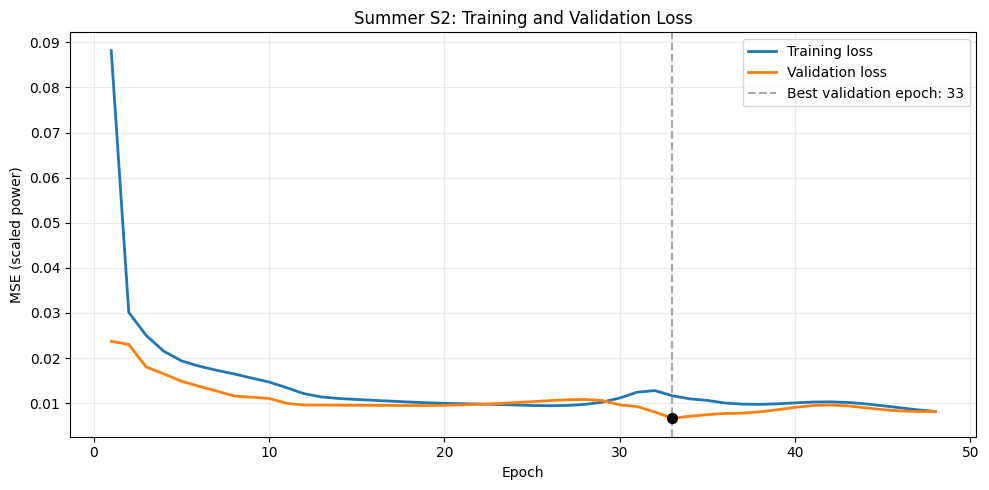

Epochs completed: 48
Best validation epoch: 33
Training MSE at that epoch:   0.011653
Validation MSE at that epoch: 0.006641


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# History from the Summer S2 training/timing cell.
training_history = benchmark_history.history

train_loss = np.asarray(training_history.get("loss", []), dtype=float)
val_loss = np.asarray(training_history.get("val_loss", []), dtype=float)

if train_loss.size == 0 or val_loss.size == 0:
    print("Loss history is unavailable.")
elif train_loss.shape != val_loss.shape:
    raise ValueError("Training and validation histories have different lengths.")
elif not (
    np.isfinite(train_loss).all()
    and np.isfinite(val_loss).all()
):
    raise ValueError("Loss history contains nonfinite values.")
else:
    epochs = np.arange(1, len(train_loss) + 1)
    best_index = int(np.argmin(val_loss))
    best_epoch = int(epochs[best_index])

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(epochs, train_loss, label="Training loss", linewidth=2)
    ax.plot(epochs, val_loss, label="Validation loss", linewidth=2)

    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        alpha=0.7,
        label=f"Best validation epoch: {best_epoch}",
    )
    ax.scatter(
        best_epoch,
        val_loss[best_index],
        color="black",
        s=50,
        zorder=5,
    )

    ax.set(
        title="Summer S2: Training and Validation Loss",
        xlabel="Epoch",
        ylabel="MSE (scaled power)",
    )
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()

    print(f"Epochs completed: {len(epochs)}")
    print(f"Best validation epoch: {best_epoch}")
    print(f"Training MSE at that epoch:   {train_loss[best_index]:.6f}")
    print(f"Validation MSE at that epoch: {val_loss[best_index]:.6f}")

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Summer"
scenario = "S2"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)

# 1. Verify all seven summer target days and four revisions.
target_dates = pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize()
labels = np.asarray(revision_labels_test)

revision_names = {
    "R0": "Rev0",
    "R1": "Rev1",
    "R2": "Rev2",
    "R3": "Rev3",
}
test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")

expected_pairs = pd.MultiIndex.from_product(
    [test_days, list(revision_names)]
)
actual_pairs = pd.MultiIndex.from_arrays([target_dates, labels])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 sample per day for June 8–14."
    )

# 2. Use the trained summer model from the timing cell.
predicted_scaled = benchmark_model.predict(
    [X_test_scaled, future_time_test],
    batch_size=16,
    verbose=0,
)
y_actual = np.asarray(y_test, dtype=np.float64).copy()

expected_shape = (len(expected_pairs), TARGET_LENGTH)

if (
    predicted_scaled.shape != expected_shape
    or y_actual.shape != expected_shape
):
    raise ValueError(
        f"Expected actual and forecast shapes: {expected_shape}."
    )

y_pred_raw = target_scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(expected_shape)

if not (
    np.isfinite(y_actual).all()
    and np.isfinite(y_pred_raw).all()
):
    raise ValueError("Actual or forecast power contains nonfinite values.")

# 3. Derive the night mask from complete SUMMER training days.
complete_training_days = []

for day, rows in train.groupby("Date", sort=True):
    rows = rows.sort_values("TimeStamp")
    expected_times = pd.date_range(
        start=pd.Timestamp(day),
        periods=BLOCKS_PER_DAY,
        freq="15min",
    )

    if pd.DatetimeIndex(rows["TimeStamp"]).equals(expected_times):
        power = rows[POWER_COLUMN].to_numpy(dtype=np.float64)

        if not np.isfinite(power).all():
            raise ValueError(f"Nonfinite training power on {day}.")

        complete_training_days.append(power)

if not complete_training_days:
    raise ValueError("No complete summer training days found.")

active_fraction = np.mean(
    np.stack(complete_training_days) > 0.1,
    axis=0,
)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

# Preserve raw forecasts; apply constraints to a separate array.
y_pred = np.maximum(y_pred_raw, 0.0)
y_pred[:, night_mask] = 0.0

# Check actual targets agree across revisions.
for day in test_days:
    day_actual = y_actual[target_dates == day]
    if not np.allclose(
        day_actual, day_actual[0], atol=1e-6, rtol=0.0
    ):
        raise ValueError(f"{day.date()}: actuals differ across revisions.")

# 4. Export one row per revision and target timestamp.
block_offsets = pd.to_timedelta(
    15 * np.arange(TARGET_LENGTH), unit="min"
)
target_times = (
    target_dates.repeat(TARGET_LENGTH)
    + np.tile(block_offsets.to_numpy(), len(target_dates))
)

predictions = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in labels],
        TARGET_LENGTH,
    ),
    "Target_Time": target_times,
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_pred.ravel(),
}).sort_values(
    ["Revision", "Target_Time"],
    ignore_index=True,
)

prediction_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Predictions"
)
prediction_dir.mkdir(parents=True, exist_ok=True)

results_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"

predictions.to_csv(
    results_path,
    index=False,
    date_format="%Y-%m-%d %H:%M",
)

print(f"Saved {len(predictions):,} rows to:")
print(results_path)

Saved 2,688 rows to:
C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S2.csv


# 11. Save Test Results

Save `y_actual`, `y_pred`, `revision_labels_test`, and `dates_test` to `scenario1_test_results.npz`. **RUN AFTER NEW PREDICTIONS ONLY.**


In [12]:
results_path = artifact_dir / "scenario2_test_results.npz"

np.savez(
    results_path,
    y_actual=y_actual,
    y_pred=y_pred,
    revision_labels=revision_labels_test,
    dates_test=dates_test.astype(str),
)

print(f"Results saved to: {results_path}")


Results saved to: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Summer\S2\scenario2_test_results.npz


# 12. Results / Demonstration

**DEMO / RESULTS ONLY**  
This section loads the saved `.npz` file and generates presentation plots without loading the model or calling `model.fit()`. It is safe to run after restarting the kernel.


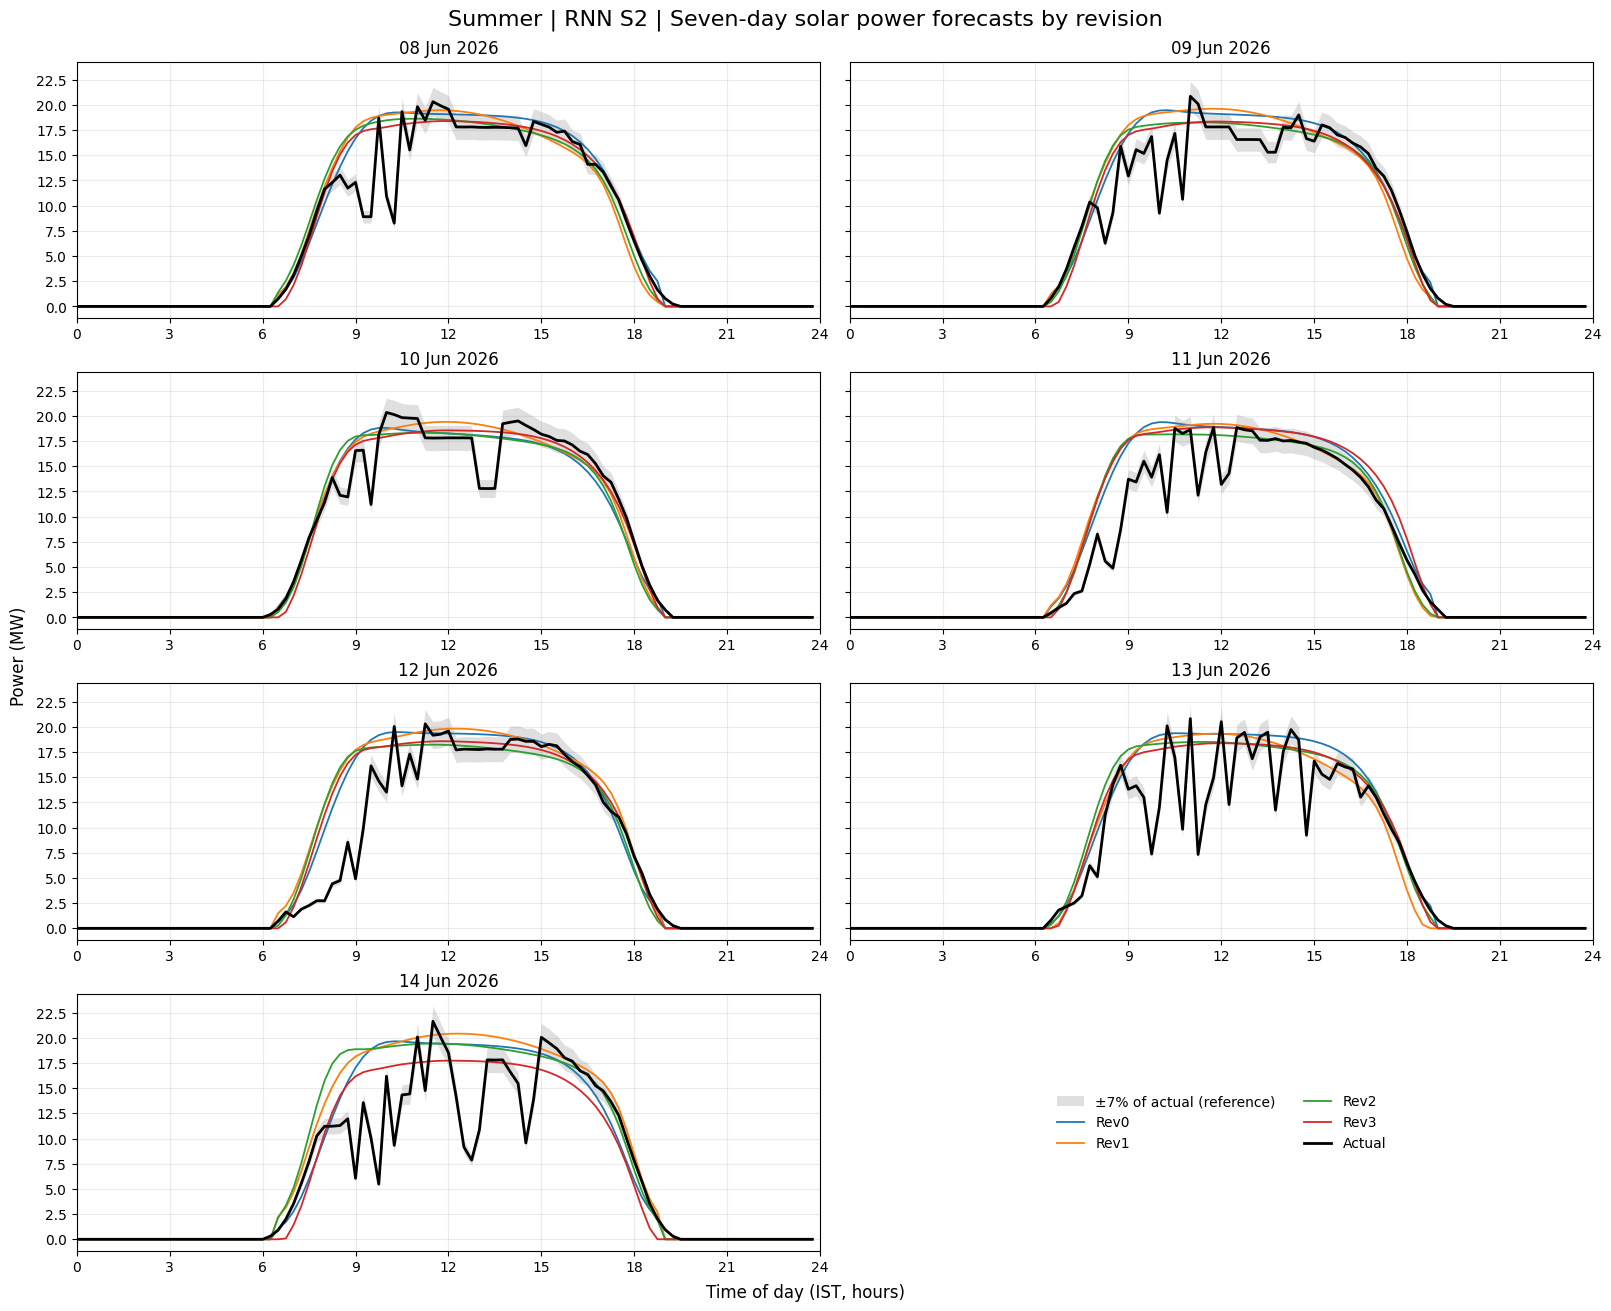

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator

# 1. Read Summer S2 predictions.
SEASON = "Summer"
scenario = "S2"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
prediction_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Predictions"
)
results_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"

data = pd.read_csv(results_path, parse_dates=["Target_Time"])

revision_colors = {
    "Rev0": "tab:blue",
    "Rev1": "tab:orange",
    "Rev2": "tab:green",
    "Rev3": "tab:red",
}
revisions = list(revision_colors)

test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")
expected_times = pd.date_range(
    test_days[0], periods=7 * 96, freq="15min"
)

# 2. Validate all 2,688 prediction rows.
expected = pd.MultiIndex.from_product(
    [expected_times, revisions],
    names=["Target_Time", "Revision"],
)
observed = data.set_index(["Target_Time", "Revision"]).index

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected exactly one Rev0–Rev3 forecast at every "
        "15-minute timestamp from June 8–14."
    )

for column in ("Actual_MW", "Forecast_MW"):
    data[column] = pd.to_numeric(data[column], errors="raise")

if not np.isfinite(
    data[["Actual_MW", "Forecast_MW"]].to_numpy()
).all():
    raise ValueError("Prediction CSV contains missing or infinite values.")

actual_by_revision = data.pivot(
    index="Target_Time",
    columns="Revision",
    values="Actual_MW",
).loc[expected_times, revisions]

actual = actual_by_revision["Rev0"]

if not np.allclose(
    actual_by_revision.to_numpy(),
    actual.to_numpy()[:, None],
    rtol=0,
    atol=1e-6,
):
    raise ValueError("Actual power differs across revisions.")

forecasts = data.pivot(
    index="Target_Time",
    columns="Revision",
    values="Forecast_MW",
).loc[expected_times, revisions]

# 3. Plot seven days using shared axes.
fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 13),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

hours = np.arange(96) / 4

for ax, day in zip(axes.flat, test_days):
    times = pd.date_range(day, periods=96, freq="15min")
    measured = actual.loc[times].to_numpy()

    # Visual reference; this is not the capacity-based DSM threshold.
    tolerance = 0.07 * np.abs(measured)

    ax.fill_between(
        hours,
        measured - tolerance,
        measured + tolerance,
        color="gray",
        alpha=0.25,
        linewidth=0,
        label="±7% of actual (reference)",
    )

    for revision, color in revision_colors.items():
        ax.plot(
            hours,
            forecasts.loc[times, revision].to_numpy(),
            color=color,
            linewidth=1.3,
            label=revision,
        )

    ax.plot(
        hours,
        measured,
        color="black",
        linewidth=2,
        label="Actual",
    )

    ax.set_title(day.strftime("%d %b %Y"))
    ax.set_xlim(0, 24)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.tick_params(axis="x", labelbottom=True)
    ax.yaxis.set_major_locator(MultipleLocator(2.5))
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

legend_ax = axes[3, 1]
legend_ax.axis("off")

handles, labels = axes[0, 0].get_legend_handles_labels()
legend_ax.legend(
    handles,
    labels,
    loc="center",
    ncol=2,
    frameon=False,
)

fig.suptitle(
    f"{SEASON} | RNN {scenario} | Seven-day solar power forecasts by revision",
    fontsize=16,
)
fig.supxlabel("Time of day (IST, hours)")
fig.supylabel("Power (MW)")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step 

VALIDATION MORNING ERRORS: 06:00–09:45
Revision   Predictions  Morning MAE MW  Morning bias MW  Near-zero actual blocks  False-positive blocks  False-positive %  Mean positive forecast at near-zero actual MW  Days with morning false positive  Days evaluated
      R0           Raw           5.942           -2.413                       54                     54           100.000                                          6.023                                28              28
      R0 Postprocessed           5.188           -3.172                       54                      2             3.704                                          0.223                                 1              28
      R1           Raw          17.875          -17.875                       54                      0             0.000                                          0.000                                 0              28
      R1 Postprocessed           9.305         

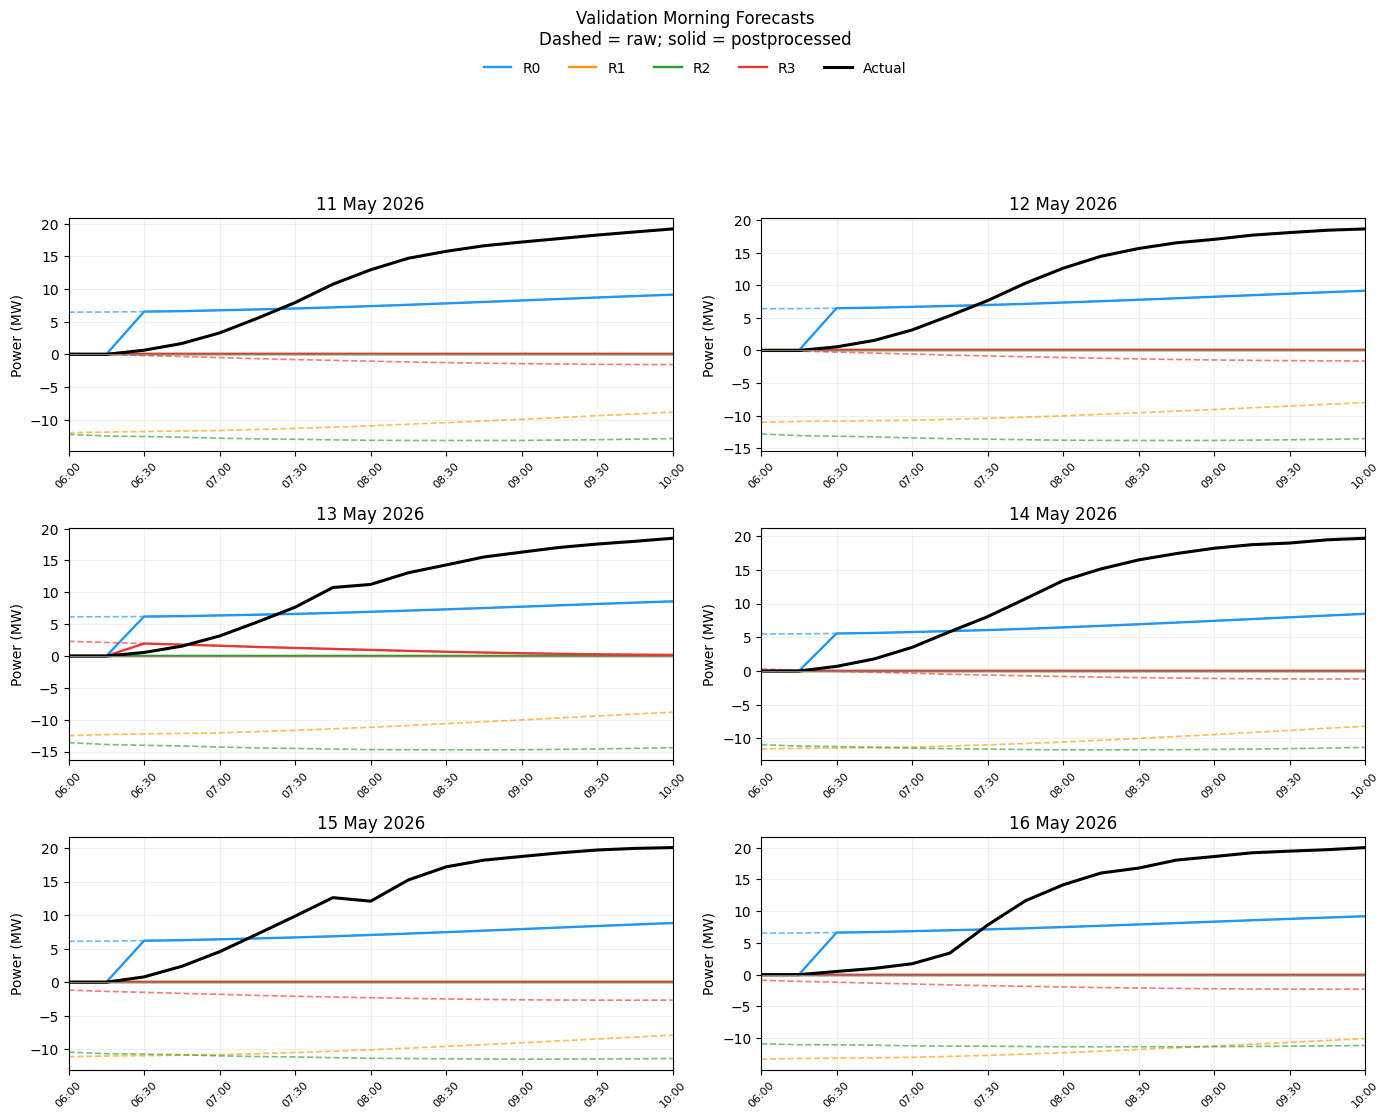

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ---------------------------------------------------------
# 1. Validation predictions in MW
# ---------------------------------------------------------
validation_predictions_scaled = model.predict(
    [X_validation_scaled, future_time_validation],
    verbose=1,
)

validation_pred_raw = target_scaler.inverse_transform(
    validation_predictions_scaled.reshape(-1, 1)
).reshape(validation_predictions_scaled.shape)

validation_actual = np.asarray(
    y_validation, dtype=np.float64
).copy()

assert validation_pred_raw.shape == validation_actual.shape
assert validation_actual.shape[1] == TARGET_LENGTH
assert np.isfinite(validation_pred_raw).all()
assert np.isfinite(validation_actual).all()

validation_pred_final = np.maximum(validation_pred_raw, 0.0)
validation_pred_final[:, night_mask] = 0.0

validation_dates = pd.DatetimeIndex(
    pd.to_datetime(dates_validation)
).normalize()

validation_labels = np.asarray(revision_labels_validation)
unique_validation_dates = validation_dates.unique().sort_values()


# ---------------------------------------------------------
# 2. Morning diagnostics across ALL validation days
# ---------------------------------------------------------
# 06:00\u201309:45. This window is for diagnosis only.
morning_positions = np.arange(24, 40)

# A reporting threshold, not a new clipping rule.
ACTIVITY_THRESHOLD_MW = 0.1


def first_active_position(curve):
    """First daily block exceeding the reporting threshold."""
    positions = np.flatnonzero(curve > ACTIVITY_THRESHOLD_MW)
    return int(positions[0]) if positions.size else None


summary_rows = []
daily_rows = []

for revision in REVISION_LENGTHS:
    indices = np.flatnonzero(validation_labels == revision)
    if indices.size == 0:
        continue

    actual_morning = validation_actual[indices][:, morning_positions]

    # Observed zero/near-zero morning blocks, used only for evaluation.
    near_zero_actual = (
        np.abs(actual_morning) <= ACTIVITY_THRESHOLD_MW
    )

    for prediction_name, predictions in (
        ("Raw", validation_pred_raw),
        ("Postprocessed", validation_pred_final),
    ):
        predicted_morning = predictions[indices][:, morning_positions]
        errors = predicted_morning - actual_morning

        false_positive = (
            near_zero_actual
            & (predicted_morning > ACTIVITY_THRESHOLD_MW)
        )

        summary_rows.append({
            "Revision": revision,
            "Predictions": prediction_name,
            "Morning MAE MW": np.mean(np.abs(errors)),
            "Morning bias MW": np.mean(errors),
            "Near-zero actual blocks": int(near_zero_actual.sum()),
            "False-positive blocks": int(false_positive.sum()),
            "False-positive %": (
                100.0 * false_positive.sum() / near_zero_actual.sum()
                if near_zero_actual.any() else np.nan
            ),
            "Mean positive forecast at near-zero actual MW": (
                np.maximum(
                    predicted_morning[near_zero_actual], 0.0
                ).mean()
                if near_zero_actual.any() else np.nan
            ),
            "Days with morning false positive": int(
                false_positive.any(axis=1).sum()
            ),
            "Days evaluated": len(indices),
        })

    for idx in indices:
        actual_start = first_active_position(validation_actual[idx])
        predicted_start = first_active_position(
            validation_pred_final[idx]
        )

        # Only compare morning starts; report unavailable otherwise.
        valid_start_comparison = (
            actual_start is not None
            and predicted_start is not None
            and actual_start < 48
            and predicted_start < 48
        )

        daily_rows.append({
            "Date": validation_dates[idx].date(),
            "Revision": revision,
            "Actual first active block": (
                actual_start + 1 if actual_start is not None else np.nan
            ),
            "Predicted first active block": (
                predicted_start + 1
                if predicted_start is not None else np.nan
            ),
            "Start error minutes": (
                15 * (predicted_start - actual_start)
                if valid_start_comparison else np.nan
            ),
        })


validation_morning_metrics = pd.DataFrame(summary_rows)
validation_start_diagnostics = pd.DataFrame(daily_rows)

print("\nVALIDATION MORNING ERRORS: 06:00\u201309:45")
print(
    validation_morning_metrics.round(3).to_string(index=False)
)

print(
    "\nFIRST ACTIVE BLOCK: postprocessed forecast versus actual\n"
    "Threshold: > 0.1 MW; negative start error = forecast starts early."
)

start_summary = (
    validation_start_diagnostics.groupby("Revision")[
        "Start error minutes"
    ]
    .agg(["count", "median", "mean"])
    .rename(columns={
        "count": "Days compared",
        "median": "Median start error min",
        "mean": "Mean start error min",
    })
)

print(start_summary.round(1).to_string())


# ---------------------------------------------------------
# 3. Plot first six validation days, selected chronologically
# ---------------------------------------------------------
plot_days = unique_validation_dates[:6]
plot_positions = np.arange(24, 41)  # 06:00\u201310:00 inclusive

colors = {
    "R0": "#2196F3",
    "R1": "#FF9800",
    "R2": "#2CA02C",
    "R3": "#E53935",
}

if len(plot_days):
    ncols = 2 if len(plot_days) > 1 else 1
    nrows = (len(plot_days) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14 if ncols == 2 else 9, 3.4 * nrows + 1),
        squeeze=False,
    )

    for ax, day in zip(axes.ravel(), plot_days):
        day_mask = np.asarray(validation_dates == day)
        day_indices = np.flatnonzero(day_mask)

        timestamps = pd.date_range(
            day, periods=TARGET_LENGTH, freq="15min"
        )
        morning_times = timestamps[plot_positions]

        for revision in REVISION_LENGTHS:
            indices = np.flatnonzero(
                day_mask & (validation_labels == revision)
            )
            assert len(indices) == 1
            idx = indices[0]

            # Dashed: model output before clipping and night masking.
            ax.plot(
                morning_times,
                validation_pred_raw[idx, plot_positions],
                color=colors[revision],
                linestyle="--",
                linewidth=1.2,
                alpha=0.65,
            )

            # Solid: forecast after existing postprocessing.
            ax.plot(
                morning_times,
                validation_pred_final[idx, plot_positions],
                color=colors[revision],
                linewidth=1.7,
                label=revision,
            )

        ax.plot(
            morning_times,
            validation_actual[day_indices[0], plot_positions],
            color="black",
            linewidth=2.2,
            label="Actual",
        )

        ax.axhline(0.0, color="gray", linewidth=0.7)
        ax.set_title(day.strftime("%d %b %Y"))
        ax.set_xticks(morning_times[::2])
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.set_xlim(morning_times[0], morning_times[-1])
        ax.set_ylabel("Power (MW)")
        ax.grid(alpha=0.2)

    for ax in axes.ravel()[len(plot_days):]:
        ax.set_visible(False)

    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        ncol=5,
        frameon=False,
    )
    fig.suptitle(
        "Validation Morning Forecasts\n"
        "Dashed = raw; solid = postprocessed",
        y=0.995,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.89])
    plt.show()


In [ ]:
import numpy as np
import pandas as pd

# Change to "Scenario 1" in the old notebook.
SCENARIO_NAME = "Scenario 2"

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1
NUMERICAL_TOLERANCE_MW = 1e-6

actual = np.asarray(y_actual, dtype=np.float64)
predicted = np.asarray(y_pred, dtype=np.float64)

assert actual.shape == predicted.shape
assert actual.ndim == 2 and actual.shape[1] == TARGET_LENGTH
assert np.isfinite(actual).all()
assert np.isfinite(predicted).all()

# Absolute width keeps bounds ordered even for negative measured values.
band_width = BAND_FRACTION * np.abs(actual)
lower_bound = actual - band_width
upper_bound = actual + band_width

inside_band = (
    (predicted >= lower_bound - NUMERICAL_TOLERANCE_MW)
    & (predicted <= upper_bound + NUMERICAL_TOLERANCE_MW)
)

rows = []

groups = {
    "Overall": np.arange(len(actual)),
    **{
        revision: np.asarray(indices, dtype=int)
        for revision, indices in revision_indices_test.items()
    },
}

for revision, indices in groups.items():
    if len(indices) == 0:
        continue

    group_actual = actual[indices]
    group_inside = inside_band[indices]

    for scope, eligible in (
        ("All blocks", np.ones(group_actual.shape, dtype=bool)),
        (
            "Active generation",
            group_actual > ACTIVE_THRESHOLD_MW,
        ),
    ):
        total = int(eligible.sum())
        inside = int((group_inside & eligible).sum())
        outside = total - inside

        rows.append({
            "Scenario": SCENARIO_NAME,
            "Revision": revision,
            "Scope": scope,
            "Evaluated blocks": total,
            "Inside \xb17%": inside,
            "Outside \xb17%": outside,
            "Inside band %": (
                100.0 * inside / total if total else np.nan
            ),
        })

band_metrics_df = pd.DataFrame(rows)

print(
    band_metrics_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)
